# trying some public packings

**Official metric on the final file: 22.24988201487** · one best packing per n, then a contact polish · lower is better.

- Scan attached public notebook outputs.
- Pick each size's shortest candidate, then certify the merged file with the official interval metric.
- Polish every size with a contact LP and keep only gains the official metric certifies.
- Keep a 1,000-row source table and a Kaggle-ready 500,500-row submission.

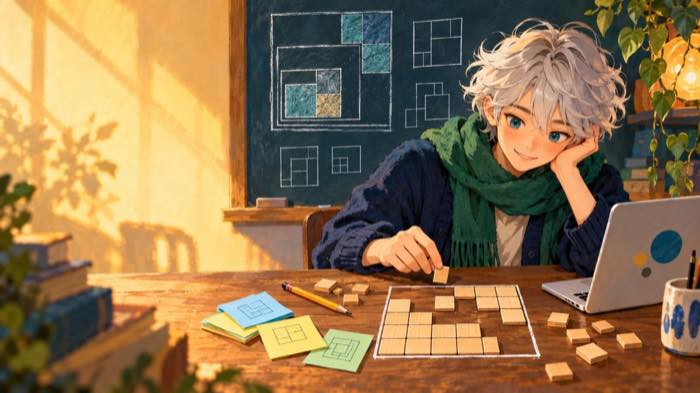

## verified blend + contact polish · 2026-11-05

The final file scores **22.24988201487** on the pinned official metric, with all 1,000 sizes valid. Rows taken from public sources are copied as they were published. The 274 polished sizes are written as shortest round-trip binary64 decimals, so a float read returns the same numbers. The next section explains the polish, and a later cell runs it live on one size.


## the contact polish · 2026-11-05

The public blends have almost converged. On 5 November the top six notebooks sat within 2e-7 of each other, and a per-size best-of across them gained only 4e-11 on the best single notebook. More candidates were no longer the way forward, so we asked a different question: **is each chosen packing actually at a local optimum?**

For 274 of 1,000 sizes it was not.

**A uniform shrink finds nothing.** Scaling every centre by 1 - 1e-15 already causes an overlap on all six sizes we tried. The room is not in the gaps as a whole. It is in squares that can still slide and turn a little against their contacts.

**The method, one packing at a time:**

1. For each close pair of squares, take the separating axis with the largest gap.
2. Linearise that gap in the six numbers of the pair: x, y and angle of each square.
3. Linearise the bounding box through the corners near its edges.
4. Solve an LP: minimise the side L, keep every gap above a small margin, and stay inside a trust box of radius r.
5. Take the step, then restore feasibility with smaller radii. Accept the cycle only if the true geometry is valid and L dropped, and adapt r.
6. Keep the result only if the official metric certifies it on both the exact route and the float64 route, and the exact score improves.

| File | Official total | Lower than the file above by |
|---|---:|---:|
| Boxed In Sub, the best public notebook when we measured | 22.24988537666 | |
| Per-size best-of | 22.24988537662 | 4.4e-11 |
| After contact polish (this notebook) | 22.24988201487 | 3.36e-06 |

Five things stand out:

- **The gains are concentrated, and they are not noise.** The ten largest supply 96% of the total; n=991 alone gives 2.8e-06.
- **Small sizes are finished.** No size below 130 moved at all.
- **Most sizes are rigid.** A private run over the 723 sizes that had not moved found a single gain of 3e-13. Those packings are on the grid or locked in place.
- **It is cheap.** The first passes took about half an hour on 8 laptop CPU cores, with no GPU. A deeper pass on the sizes that moved takes hours, and it is still finding room: n=991 was improving when it hit its time limit.
- **It is a small win next to the real gap.** The best teams on the leaderboard sit near 22.05, about 0.2 lower than every public notebook. Polish closes less than 1e-5 of that, so the rest must come from better structures, not better decimals.

Polishing is not a new idea in this competition. See [Certified Contact Polish](https://www.kaggle.com/code/sigmaborov/squares-in-squares-certified-contact-polish) by sigmaborov and [Hybrid SLP Basin-Hopper](https://www.kaggle.com/code/nilanjansaha123/hybrid-slp-basin-hopper-t4x2) by Nilanjan Saha. What this pass adds is running it after the blend, on every size, as the last step before certification.

**Where the starting packings came from.** Ties go to the first source, so the first row includes sizes where several public notebooks hold the same packing.

| Source | Sizes selected before the polish |
|---|---:|
| our earlier blend, itself built from the credited public outputs in this notebook | 755 |
| [Boxed In Sub](https://www.kaggle.com/code/jazivxt/boxed-in-sub), jazivxt | 209 |
| [Squares 101](https://www.kaggle.com/code/alexchilton/squares-101-the-starter-kit-7-500-downloads), alex chilton | 18 |
| [22.2499 CPU/CUDA/MPS](https://www.kaggle.com/code/kirilltym/22-2499-cpu-cuda-mps-eda-budget-lp), Kirill Tymchishin | 15 |
| [Certified Contact Polish](https://www.kaggle.com/code/sigmaborov/squares-in-squares-certified-contact-polish), sigmaborov | 3 |

The data and the full tool are in the dataset [squares-verified-best-of-1105](https://www.kaggle.com/datasets/prvsiyan/squares-verified-best-of-1105): `submission.csv`, `per_n_polish.csv` and `contact_polish_full.py`, with `float_gate.py` and `official_metric.py` beside it so the tool runs as it stands. The live cell below uses a simpler fixed schedule so it finishes in under a minute.


In [ ]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import base64, csv, hashlib, json, math, time, warnings, zlib
from collections import defaultdict
from decimal import Decimal, localcontext
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon
from IPython.display import Markdown, display

INPUT_ROOT = Path("/kaggle/input")
WORK_DIR = Path("/kaggle/working")
WORK_DIR.mkdir(parents=True, exist_ok=True)
KERNEL_SOURCES = ["busyaprime/lb-22-2616222-best-public-packings-fq-quench", "evgendvorkin/squares-in-squares-deep-eda-analogies", "lostdecimal27/squares-in-squares-bands-gadgets-exact-angles", "malyshevdanil/squares-in-squares-living-atlas-of-tight-packings", "nilanjansaha123/s-in-s-certified-portfolio-merge-proj-quench", "prvsiyan/auto-updater", "sigmaborov/squares-in-squares-certified-contact-polish", "woshichenyanyan/notebook0ec4821c3d"]
SOURCE_TITLES = {"busyaprime/lb-22-2616222-best-public-packings-fq-quench": "LB 22.2616222 best public packings FQ quench", "evgendvorkin/squares-in-squares-deep-eda-analogies": "🧩 Squares in Squares | Deep EDA & Analogies", "lostdecimal27/squares-in-squares-bands-gadgets-exact-angles": "Squares in Squares: Bands, Gadgets, Exact Angles", "malyshevdanil/squares-in-squares-living-atlas-of-tight-packings": "squares-in-squares-living-atlas-of-tight-packings", "nilanjansaha123/s-in-s-certified-portfolio-merge-proj-quench": "s-in-s-certified-portfolio-merge-proj-quench", "prvsiyan/auto-updater": "auto-updater latest output fetched at task start", "sigmaborov/squares-in-squares-certified-contact-polish": "squares-in-squares-certified-contact-polish", "woshichenyanyan/notebook0ec4821c3d": "notebook0ec4821c3d"}
REQUIRED_COLUMNS = {"n", "square_id", "x", "y", "angle"}
NON_SUBMISSION_FILES = {"submission_details.csv", "submission_sources.csv"}
WARNINGS = []
print(f"attached sources: {len(KERNEL_SOURCES)}")


## the handoff

`8 public outputs` → one candidate list per n → official interval check → source table + submission.

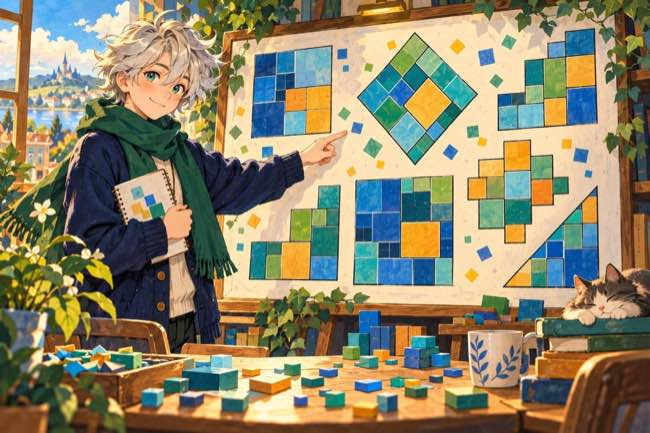

The compact dots below are written by code, so the diagram stays tied to the files found in this run.

In [ ]:
def source_matches(path, ref):
    owner, slug = ref.split("/", 1)
    names = {part.lower() for part in path.parts}
    combined = {owner.lower() + "-" + slug.lower(), owner.lower() + "_" + slug.lower()}
    return slug.lower() in names or bool(names & combined) or (owner.lower() in names and slug.lower() in names)


def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def add_warning(message):
    WARNINGS.append(message)
    print("WARNING:", message)


source_files = defaultdict(list)
if not INPUT_ROOT.is_dir():
    add_warning("/kaggle/input is missing; every size will use the grid fallback")
else:
    for path in INPUT_ROOT.rglob("submission*.csv"):
        if path.name.lower() in NON_SUBMISSION_FILES:
            continue
        try:
            with path.open("r", encoding="utf-8-sig", newline="") as stream:
                header = next(csv.reader(stream), [])
            if not REQUIRED_COLUMNS.issubset({item.strip() for item in header}):
                continue
        except (OSError, UnicodeError):
            continue
        matches = [ref for ref in KERNEL_SOURCES if source_matches(path, ref)]
        if len(matches) == 1:
            source_files[matches[0]].append(path)
        elif len(matches) > 1:
            matches.sort(key=len, reverse=True)
            source_files[matches[0]].append(path)
        else:
            add_warning(f"unmapped submission file: {path}")

missing_sources = [ref for ref in KERNEL_SOURCES if not source_files[ref]]
for ref in missing_sources:
    add_warning(f"attached source has no coordinate submission output: {ref}")
print(f"sources with output files: {sum(bool(v) for v in source_files.values())}/{len(KERNEL_SOURCES)}")


In [ ]:
"""Metric for the "Packing N Unit Squares into the Smallest Square" competition.

Participants submit packings of n unit squares (n=1..1000) inside a bounding
square.  Each square is specified by its center (x, y) and rotation angle.
Coordinates must be plain decimal literals, optionally in scientific notation
(e.g. ``2.70710678118654752440`` or ``1.5e-3``).  Symbolic / closed-form
expressions are not accepted -- submit their decimal expansion instead, at as
many digits as you like.

Scoring
-------
For each puzzle n the bounding side length L is measured
translation-invariantly as ``max(max_x - min_x, max_y - min_y)`` over all
corners.  The per-puzzle score is the excess over the area lower bound

    score(n) = L / sqrt(n) - 1

which is 0.0 exactly when the packing achieves the area lower bound (only
possible for perfect squares packed on the grid) and grows above 0 as the
bounding square wastes area.  **Lower is better**; total score is the sum
across n=1..N.

+-------------------+---------------------------------------------------------+
| Condition         | Score                                                   |
+===================+=========================================================+
| feasible packing  | L / sqrt(n) - 1     (>= 0 always)                       |
+-------------------+---------------------------------------------------------+
| infeasible/invalid| L_0 / sqrt(n) - 1   (grid ceiling — no worse than       |
|                   |                      submitting the trivial grid)       |
+-------------------+---------------------------------------------------------+

For reference: ``L_B = sqrt(n)`` is the area lower bound and
``L_0 = ceil(sqrt(n))`` is the trivial grid packing.  The best-known side
length plays no part -- beating a record just yields a smaller excess -- so
this metric reads no baseline values at all.

Feasibility is checked with interval arithmetic (mpmath) at escalating
precision to certify that no two squares overlap.

Kaggle entry point
------------------
``score(solution, submission, row_id_column_name)`` — called by the Kaggle
backend.  ``solution`` is a DataFrame loaded from ``solution.csv``; only its
``n`` column is read, to fix which puzzles are scored (and which absent ones
are charged the grid ceiling).  ``submission`` is the participant CSV with
columns ``n, square_id, x, y, angle``.

As a side effect it writes ``submission_details.csv``, one row per puzzle with
columns ``n`` and ``L``::

    n,L
    1,1.00000000000000000000000000000000000000000000000000
    2,2.00000000000000000000000000000000000000000000000000
    ...

``L`` is the measured bounding side for puzzle n -- not the per-puzzle score --
written with exactly 50 digits after the decimal point.  Those digits are
significant: L is measured in ``L_DPS``-digit mpmath arithmetic straight from
the submitted decimal strings, not from a double.  Puzzles with no accepted L
(absent from the submission, unparseable, failing column validation, or
rejected as infeasible) are written as zero.
"""

import contextlib
import csv
import io
import math
import multiprocessing
import re
from collections import defaultdict
from collections.abc import Callable, Sequence
from dataclasses import dataclass, field
from fractions import Fraction
from pathlib import Path

import mpmath
import pandas as pd

# ---------------------------------------------------------------------------
# interval
# ---------------------------------------------------------------------------

IVal = mpmath.ctx_iv.ivmpf

# Working precision for the (non-interval) measurement of the bounding side L,
# and the number of digits after the decimal point written for it in
# submission_details.csv.  The margin between the two keeps every written digit
# correct: the only rounding is in the trig of the corner computation, tens of
# digits below the last digit reported.
L_DPS = 60
L_DECIMALS = 50


@contextlib.contextmanager
def working_dps(dps: int):
    """Run a block with both mpmath contexts at ``dps`` digits, then restore them.

    ``mpmath.iv`` carries its own precision, independent of ``mpmath.mp``:
    setting only ``mpmath.mp.dps`` leaves every interval operation at the
    default 53 bits, which caps what a contact can be certified to at ~1e-13 no
    matter how far the escalation sequence climbs.  Both contexts are set here
    because the interval work is interleaved with plain ``mp`` arithmetic.

    >>> with working_dps(500):
    ...     width = mpmath.mpf(mpmath.iv.mpf('0.1').delta)
    >>> width < mpmath.mpf(10) ** -500
    True
    """
    old_iv_dps = mpmath.iv.dps
    old_mp_dps = mpmath.mp.dps
    try:
        mpmath.iv.dps = dps
        mpmath.mp.dps = dps
        yield
    finally:
        mpmath.iv.dps = old_iv_dps
        mpmath.mp.dps = old_mp_dps


def make_interval(value: str, dps: int = 50) -> IVal:
    with working_dps(dps):
        return mpmath.iv.mpf(value)


def iv_cos(x: IVal) -> IVal:
    return mpmath.iv.cos(x)


def iv_sin(x: IVal) -> IVal:
    return mpmath.iv.sin(x)


_ESCALATION_SEQUENCE = [50, 100, 200, 500]


def escalate(
    fn: Callable[[int], bool | None],
    max_dps: int = 500,
    start_dps: int = 50,
) -> bool | None:
    for dps in _ESCALATION_SEQUENCE:
        if dps < start_dps:
            continue
        if dps > max_dps:
            break
        result = fn(dps)
        if result is not None:
            return result
    return None


def iv_le(a: IVal, b: IVal) -> bool | None:
    """Certified less-or-equal: True if a <= b, False if a > b, None if undecided.

    Comparing two overlapping intervals is indeterminate.  mpmath 1.3 reports
    that as None, 1.4 raises ValueError; both mean "undecided" here.
    """
    try:
        return a <= b
    except ValueError:
        return None


def iv_min(values: Sequence[IVal]) -> IVal:
    """Interval extension of ``min``: the tightest interval containing the true minimum.

    Comparison operators are useless for this -- two overlapping intervals have
    no determinate order -- so take it endpoint-wise instead.  min of the lower
    bounds is a lower bound on the true min, and min of the upper bounds is an
    upper bound on it, whichever element turns out to be smallest.
    """
    return mpmath.iv.mpf([min(v.a for v in values), min(v.b for v in values)])


def iv_max(values: Sequence[IVal]) -> IVal:
    """Interval extension of ``max``. See :func:`iv_min`."""
    return mpmath.iv.mpf([max(v.a for v in values), max(v.b for v in values)])


# ---------------------------------------------------------------------------
# parser
# ---------------------------------------------------------------------------

# Bounds the cost of parsing one coordinate.  Far above any useful precision
# (L is reported to 50 decimals), so no honest submission comes near it.
_MAX_LITERAL_CHARS = 100

# Coordinate, angle, and sweep bounds.  For n <= 1000 unit squares, valid
# packings have side L <= 32.  Bounding magnitudes prevents float64/mpmath
# discrepancies and precision loss under extreme translation or rotation.
_MAX_COORD = 1e4
_MAX_ANGLE = 100.0
_AABB_PAD = 1e-7

_DECIMAL_RE = re.compile(r'^[+-]?(\d+\.?\d*|\.\d+)([eE][+-]?\d+)?$')


def _is_decimal(s: str) -> bool:
    return len(s) <= _MAX_LITERAL_CHARS and bool(_DECIMAL_RE.match(s.strip()))


def _check_decimal(s: str) -> str:
    """Return the stripped literal, or raise if it is not a plain decimal.

    >>> _check_decimal(" 2.70710678118654752440 ")
    '2.70710678118654752440'
    >>> _check_decimal("1.5e-3")
    '1.5e-3'
    >>> _check_decimal("1 + sqrt(2)")
    Traceback (most recent call last):
        ...
    ValueError: not a decimal number: '1 + sqrt(2)'
    """
    s = s.strip()
    if not _is_decimal(s):
        shown = s if len(s) <= 40 else s[:40] + '...'
        raise ValueError(f'not a decimal number: {shown!r}')
    return s


def parse_value(s: str, dps: int = 50) -> IVal:
    """Parse a decimal literal into an enclosing interval at ``dps`` digits."""
    return make_interval(_check_decimal(s), dps)


def parse_value_mp(s: str, dps: int = L_DPS) -> mpmath.mpf:
    """Parse a decimal literal into an ``mpf`` at ``dps`` digits.

    >>> mpmath.nstr(parse_value_mp("2.70710678118654752440"), 21, strip_zeros=False)
    '2.70710678118654752440'
    """
    s = _check_decimal(s)
    old_dps = mpmath.mp.dps
    try:
        mpmath.mp.dps = dps
        return mpmath.mpf(s)
    finally:
        mpmath.mp.dps = old_dps


def parse_value_float(s: str) -> float:
    """Parse a decimal literal to float.

    Values too large for a double are rejected rather than becoming ``inf``,
    which would poison every downstream geometry check:

    >>> parse_value_float("3.5")
    3.5
    >>> parse_value_float("-2.5")
    -2.5
    >>> parse_value_float("1.5e-3")
    0.0015
    >>> parse_value_float("1e400")
    Traceback (most recent call last):
        ...
    ValueError: value out of range for a double: '1e400'
    """
    s = _check_decimal(s)
    value = float(s)
    if not math.isfinite(value):
        raise ValueError(f'value out of range for a double: {s!r}')
    return value


# ---------------------------------------------------------------------------
# scoring
# ---------------------------------------------------------------------------


def score_puzzle(n: int, s_certified: float) -> float:
    """Score a single puzzle: L / sqrt(n) - 1 (lower is better).

    Result is >= 0 for any feasible packing (equality only for perfect-square
    grid packings).  The best-known side length s* plays no part: beating a
    record simply yields a smaller excess.

    >>> score_puzzle(4, 2.0)
    0.0
    >>> round(score_puzzle(5, 2.707), 6)
    0.210607
    >>> score_puzzle(4, 4.0)
    1.0
    """
    L_B = math.sqrt(n)
    return s_certified / L_B - 1.0


def infeasible_score(n: int) -> float:
    """Penalty score for an infeasible / invalid submission for puzzle n.

    Equal to submitting the trivial grid packing: L_0 / sqrt(n) - 1.
    """
    return math.ceil(math.sqrt(n)) / math.sqrt(n) - 1.0


# ---------------------------------------------------------------------------
# geometry
# ---------------------------------------------------------------------------


@dataclass
class Square:
    x: float
    y: float
    angle: float
    x_str: str = ''
    y_str: str = ''
    angle_str: str = ''
    _corners_float: list[tuple[float, float]] = field(default_factory=list, repr=False)

    def corners_float(self) -> list[tuple[float, float]]:
        if not self._corners_float:
            self._corners_float = compute_corners_float(self.x, self.y, self.angle)
        return self._corners_float


def compute_corners_float(cx: float, cy: float, angle: float) -> list[tuple[float, float]]:
    """Return the four corners of a unit square centered at (cx, cy) rotated by angle.

    >>> corners = compute_corners_float(0.5, 0.5, 0.0)
    >>> [(round(x, 1), round(y, 1)) for x, y in corners]
    [(1.0, 1.0), (0.0, 1.0), (0.0, 0.0), (1.0, 0.0)]
    """
    c = math.cos(angle)
    s = math.sin(angle)
    h = 0.5
    dx1, dy1 = h * c - h * s, h * s + h * c
    dx2, dy2 = -h * c - h * s, -h * s + h * c
    return [
        (cx + dx1, cy + dy1),
        (cx + dx2, cy + dy2),
        (cx - dx1, cy - dy1),
        (cx - dx2, cy - dy2),
    ]


def compute_corners_mp(cx: mpmath.mpf, cy: mpmath.mpf, angle: mpmath.mpf) -> list[tuple[mpmath.mpf, mpmath.mpf]]:
    """``compute_corners_float`` at the ambient ``mpmath.mp`` precision."""
    c = mpmath.cos(angle)
    s = mpmath.sin(angle)
    h = mpmath.mpf(1) / 2
    dx1, dy1 = h * c - h * s, h * s + h * c
    dx2, dy2 = -h * c - h * s, -h * s + h * c
    return [
        (cx + dx1, cy + dy1),
        (cx + dx2, cy + dy2),
        (cx - dx1, cy - dy1),
        (cx - dx2, cy - dy2),
    ]


def measure_side_mp(squares: list['Square'], dps: int = L_DPS) -> mpmath.mpf:
    """Bounding side ``max(max_x - min_x, max_y - min_y)`` at ``dps`` digits.

    Measured from the submitted decimal strings translated relative to Square 0,
    so coordinates carry high precision without loss due to global translation.

    >>> unit = Square(0.5, 0.5, 0.0, x_str="0.5", y_str="0.5", angle_str="0")
    >>> measure_side_mp([unit])
    mpf('1.0')
    """
    old_dps = mpmath.mp.dps
    try:
        mpmath.mp.dps = dps
        xs: list[mpmath.mpf] = []
        ys: list[mpmath.mpf] = []
        x0 = parse_value_mp(squares[0].x_str, dps) if squares else mpmath.mpf(0)
        y0 = parse_value_mp(squares[0].y_str, dps) if squares else mpmath.mpf(0)
        for sq in squares:
            corners = compute_corners_mp(
                parse_value_mp(sq.x_str, dps) - x0,
                parse_value_mp(sq.y_str, dps) - y0,
                parse_value_mp(sq.angle_str, dps),
            )
            for x, y in corners:
                xs.append(x)
                ys.append(y)
        return max(max(xs) - min(xs), max(ys) - min(ys))
    finally:
        mpmath.mp.dps = old_dps


def compute_corners_interval(cx_iv: IVal, cy_iv: IVal, angle_iv: IVal) -> list[tuple[IVal, IVal]]:
    c = iv_cos(angle_iv)
    s = iv_sin(angle_iv)
    h = mpmath.iv.mpf('0.5')
    dx1, dy1 = h * c - h * s, h * s + h * c
    dx2, dy2 = -h * c - h * s, -h * s + h * c
    return [
        (cx_iv + dx1, cy_iv + dy1),
        (cx_iv + dx2, cy_iv + dy2),
        (cx_iv - dx1, cy_iv - dy1),
        (cx_iv - dx2, cy_iv - dy2),
    ]


def compute_aabb(
    corners: list[tuple[float, float]],
    pad: float = _AABB_PAD,
) -> tuple[float, float, float, float]:
    xs = [c[0] for c in corners]
    ys = [c[1] for c in corners]
    return (min(xs) - pad, min(ys) - pad, max(xs) + pad, max(ys) + pad)


def aabb_overlap(
    a: tuple[float, float, float, float],
    b: tuple[float, float, float, float],
) -> bool:
    return not (a[2] < b[0] or b[2] < a[0] or a[3] < b[1] or b[3] < a[1])


def _project_corners_float(corners: list[tuple[float, float]], ax: float, ay: float) -> tuple[float, float]:
    projs = [ax * cx + ay * cy for cx, cy in corners]
    return (min(projs), max(projs))


def sat_check_float(sq1: Square, sq2: Square, undecided_tol: float = 1e-8) -> str:
    """Check overlap between two unit squares using the Separating Axis Theorem.

    Returns ``"separated"``, ``"overlapping"``, or ``"undecided"``.

    >>> sat_check_float(Square(0.5, 0.5, 0.0), Square(5.0, 5.0, 0.0))
    'separated'
    >>> sat_check_float(Square(0.5, 0.5, 0.0), Square(0.6, 0.6, 0.0))
    'overlapping'
    """
    c1 = sq1.corners_float()
    c2 = sq2.corners_float()

    axes = _get_axes_float(sq1.angle, sq2.angle)

    min_overlap = float('inf')
    for ax, ay in axes:
        min1, max1 = _project_corners_float(c1, ax, ay)
        min2, max2 = _project_corners_float(c2, ax, ay)
        overlap = min(max1, max2) - max(min1, min2)
        if overlap < -undecided_tol:
            return 'separated'
        min_overlap = min(min_overlap, overlap)

    if min_overlap > undecided_tol:
        return 'overlapping'
    return 'undecided'


def _get_axes_float(angle1: float, angle2: float) -> list[tuple[float, float]]:
    c1, s1 = math.cos(angle1), math.sin(angle1)
    c2, s2 = math.cos(angle2), math.sin(angle2)
    return [(c1, s1), (-s1, c1), (c2, s2), (-s2, c2)]


def sat_check_interval(
    sq1_corners: list[tuple[IVal, IVal]],
    sq2_corners: list[tuple[IVal, IVal]],
    angle1_iv: IVal,
    angle2_iv: IVal,
) -> bool | None:
    c1_iv, s1_iv = iv_cos(angle1_iv), iv_sin(angle1_iv)
    c2_iv, s2_iv = iv_cos(angle2_iv), iv_sin(angle2_iv)
    axes = [(c1_iv, s1_iv), (-s1_iv, c1_iv), (c2_iv, s2_iv), (-s2_iv, c2_iv)]

    has_undecided = False
    for ax, ay in axes:
        projs1 = [ax * cx + ay * cy for cx, cy in sq1_corners]
        projs2 = [ax * cx + ay * cy for cx, cy in sq2_corners]

        # Endpoint-wise, via iv_min/iv_max: ordering two overlapping intervals
        # with < is indeterminate, and skipping the projections that compare
        # indeterminately would narrow the span -- which shrinks the overlap and
        # biases the test towards wrongly certifying a pair as separated.
        min1, max1 = iv_min(projs1), iv_max(projs1)
        min2, max2 = iv_min(projs2), iv_max(projs2)

        overlap = iv_min([max1, max2]) - iv_max([min1, min2])
        le_result = iv_le(overlap, mpmath.iv.mpf('0'))
        if le_result is True:
            return True
        if le_result is None:
            has_undecided = True

    if has_undecided:
        return None
    return False


def sort_and_sweep(squares: list[Square]) -> list[tuple[int, int]]:
    n = len(squares)
    if n <= 1:
        return []

    aabbs = []
    for i, sq in enumerate(squares):
        corners = sq.corners_float()
        aabb = compute_aabb(corners)
        aabbs.append((i, aabb))

    aabbs.sort(key=lambda x: x[1][0])

    pairs = []
    for i_idx in range(n):
        i, aabb_i = aabbs[i_idx]
        for j_idx in range(i_idx + 1, n):
            j, aabb_j = aabbs[j_idx]
            if aabb_j[0] > aabb_i[2]:
                break
            if aabb_overlap(aabb_i, aabb_j):
                pairs.append((i, j) if i < j else (j, i))

    return pairs


def verify_puzzle(
    squares: list[Square],
) -> tuple[bool, str]:
    """Check that no two squares overlap, using float SAT then interval arithmetic.

    >>> s1 = Square(0.5, 0.5, 0.0, x_str="0.5", y_str="0.5", angle_str="0")
    >>> s2 = Square(1.5, 0.5, 0.0, x_str="1.5", y_str="0.5", angle_str="0")
    >>> verify_puzzle([s1, s2])
    (True, 'feasible')
    >>> verify_puzzle([Square(0.5, 0.5, 0.0), Square(0.6, 0.6, 0.0)])
    (False, 'Squares 0 and 1 overlap (float check)')
    """
    pairs = sort_and_sweep(squares)
    undecided_pairs = []
    for i, j in pairs:
        result = sat_check_float(squares[i], squares[j])
        if result == 'overlapping':
            return (False, f'Squares {i} and {j} overlap (float check)')
        if result == 'undecided':
            undecided_pairs.append((i, j))

    if undecided_pairs:

        def check_overlap_certified(dps: int) -> bool | None:
            # The whole pair loop runs inside the precision context: parsing at dps
            # digits is not enough, since every later interval operation widens its
            # result to whatever precision mpmath.iv is set to at the time.
            with working_dps(dps):
                still_undecided = []
                for i, j in undecided_pairs:
                    sq_i, sq_j = squares[i], squares[j]
                    cx_i = parse_value(sq_i.x_str, dps)
                    cy_i = parse_value(sq_i.y_str, dps)
                    ai = parse_value(sq_i.angle_str, dps)
                    cx_j = parse_value(sq_j.x_str, dps)
                    cy_j = parse_value(sq_j.y_str, dps)
                    aj = parse_value(sq_j.angle_str, dps)
                    corners_i = compute_corners_interval(cx_i, cy_i, ai)
                    corners_j = compute_corners_interval(cx_j, cy_j, aj)
                    result = sat_check_interval(corners_i, corners_j, ai, aj)
                    if result is False:
                        return False
                    if result is None:
                        still_undecided.append((i, j))
                if still_undecided:
                    return None
                return True

        result = escalate(check_overlap_certified)
        if result is False:
            return (False, 'Squares overlap (certified)')
        if result is None:
            return (False, 'Overlap undecidable at max precision')

    return (True, 'feasible')


# ---------------------------------------------------------------------------
# main / Kaggle entry point
# ---------------------------------------------------------------------------


class ParticipantVisibleError(Exception):
    pass


MAX_N = 1000
KAGGLE_CORES = 4
MIN_PUZZLES_FOR_MP = 4


def _parse_submission_csv(text: str) -> dict[int, list[dict]]:
    reader = csv.DictReader(io.StringIO(text))
    required_cols = {'n', 'square_id', 'x', 'y', 'angle'}
    if not required_cols.issubset(set(reader.fieldnames or [])):
        missing = required_cols - set(reader.fieldnames or [])
        raise ParticipantVisibleError(f'Missing columns: {missing}')

    puzzles: dict[int, list[dict]] = defaultdict(list)
    for row_num, row in enumerate(reader, start=2):
        try:
            n = int(row['n'])
        except (ValueError, TypeError):
            raise ParticipantVisibleError(f'Row {row_num}: invalid n value: {row["n"]!r}')
        if n < 1 or n > MAX_N:
            raise ParticipantVisibleError(f'Row {row_num}: n={n} out of range [1, {MAX_N}]')
        puzzles[n].append(row)

    return dict(puzzles)


def _validate_puzzle(n: int, rows: list[dict]) -> str | None:
    if len(rows) != n:
        return f'n={n}: expected {n} rows, got {len(rows)}'

    square_ids = set()
    for row in rows:
        try:
            sid = int(row['square_id'])
        except (ValueError, TypeError):
            return f'n={n}: invalid square_id: {row["square_id"]!r}'
        square_ids.add(sid)

    expected_ids = set(range(n))
    if square_ids != expected_ids:
        return f'n={n}: square_ids should be 0..{n - 1}, got {sorted(square_ids)}'

    return None


def _build_squares(n: int, rows: list[dict]) -> tuple[list[Square], mpmath.mpf]:
    rows_by_id = {int(r['square_id']): r for r in rows}

    raw_coords = []
    for sid in range(n):
        row = rows_by_id[sid]
        x_str = row['x'].strip()
        y_str = row['y'].strip()
        angle_str = row['angle'].strip()

        try:
            x_f = parse_value_float(x_str)
            y_f = parse_value_float(y_str)
            angle_f = parse_value_float(angle_str)
        except ValueError as e:
            raise ParticipantVisibleError(f'n={n}, square {sid}: cannot parse coordinates: {e}')

        if abs(x_f) > _MAX_COORD or abs(y_f) > _MAX_COORD:
            raise ParticipantVisibleError(f'n={n}, square {sid}: coordinate out of bounds (|x|, |y| must be <= {_MAX_COORD:g})')
        if abs(angle_f) > _MAX_ANGLE:
            raise ParticipantVisibleError(f'n={n}, square {sid}: angle out of bounds (|angle| must be <= {_MAX_ANGLE:g} radians)')

        raw_coords.append((sid, x_str, y_str, angle_str))

    x0_mp = parse_value_mp(raw_coords[0][1], L_DPS)
    y0_mp = parse_value_mp(raw_coords[0][2], L_DPS)
    two_pi = 2 * mpmath.pi

    squares = []
    for sid, x_str, y_str, angle_str in raw_coords:
        x_mp = parse_value_mp(x_str, L_DPS)
        y_mp = parse_value_mp(y_str, L_DPS)
        angle_mp = parse_value_mp(angle_str, L_DPS)

        dx_f = float(x_mp - x0_mp)
        dy_f = float(y_mp - y0_mp)
        angle_reduced_f = float(angle_mp % two_pi)

        squares.append(
            Square(
                x=dx_f,
                y=dy_f,
                angle=angle_reduced_f,
                x_str=x_str,
                y_str=y_str,
                angle_str=angle_str,
            )
        )

    return squares, measure_side_mp(squares)


def evaluate_single_puzzle(n: int, rows: list[dict]) -> tuple[int, float, str | None, str]:
    """Evaluate one puzzle, returning ``(n, score, L, reason)``.

    ``L`` is decimal text with ``L_DECIMALS`` digits after the point, and is
    reported only for a packing that passed the feasibility check: an
    unparseable, malformed, or overlapping puzzle gets None, so no L is
    published for a packing the metric rejected.  Text rather than a float
    because a double cannot hold those digits; the score itself is a double,
    taken from the same high-precision measurement.
    """
    error = _validate_puzzle(n, rows)
    if error:
        return (n, infeasible_score(n), None, error)

    try:
        squares, s_mp = _build_squares(n, rows)
    except ParticipantVisibleError as e:
        return (n, infeasible_score(n), None, str(e))

    feasible, reason = verify_puzzle(squares)
    if not feasible:
        return (n, infeasible_score(n), None, f'infeasible: {reason}')

    L_B = math.sqrt(n)
    if float(s_mp) < L_B - 1e-7:
        return (
            n,
            infeasible_score(n),
            None,
            f'infeasible: L={float(s_mp):.6f} is below area lower bound sqrt({n})={L_B:.6f}',
        )

    puzzle_score = max(0.0, score_puzzle(n, float(s_mp)))
    return (n, puzzle_score, _format_detail(s_mp), 'ok')


def _evaluate_puzzle_worker(args: tuple) -> tuple[int, float, str | None, str]:
    n, rows = args
    try:
        return evaluate_single_puzzle(n, rows)
    except Exception as e:  # noqa: BLE001 - one bad puzzle must not kill the pool
        return (n, infeasible_score(n), None, f'worker error: {e}')


def _evaluate_puzzles_parallel(
    puzzles: dict[int, list[dict]],
    puzzle_ns: set[int],
) -> tuple[float, list[tuple[int, float, str | None, str]]]:
    """Score every n in ``puzzle_ns``; rows for any other n are ignored."""
    work = [(n, rows) for n, rows in sorted(puzzles.items()) if n in puzzle_ns]

    if not work:
        results: list[tuple[int, float, str | None, str]] = []
    elif len(work) < MIN_PUZZLES_FOR_MP:
        results = [evaluate_single_puzzle(n, rows) for n, rows in work]
    else:
        with multiprocessing.Pool(processes=KAGGLE_CORES) as pool:
            results = pool.map(_evaluate_puzzle_worker, work)

    # Any scored n missing from the submission gets the grid-ceiling penalty
    # (lower-is-better metric — otherwise omitting a puzzle would improve the
    # total).
    seen = {n for n, _, _, _ in results}
    for n in puzzle_ns:
        if n not in seen:
            results.append((n, infeasible_score(n), None, 'missing from submission'))
    results.sort(key=lambda r: r[0])

    total = sum(puzzle_score for _, puzzle_score, _, _ in results)
    return total, results


def _format_detail(value: mpmath.mpf) -> str:
    """Decimal text for one per-puzzle L: exactly ``L_DECIMALS`` digits after the point.

    An ``mpf`` is a binary fraction (``man * 2**exp``), so it is converted
    exactly to a ``Fraction`` and rounded once, half-to-even, at the last
    written digit.  ``mpmath.nstr`` counts significant digits rather than
    decimal places, and ``format(mpf, '.50f')`` needs mpmath >= 1.4, so neither
    is usable here.

    >>> _format_detail(mpmath.mpf(2))[:12]
    '2.0000000000'
    >>> len(_format_detail(mpmath.mpf(2)).split('.')[1])
    50
    >>> _format_detail(parse_value_mp('1.41421356237309504880168872420969807856967187537695'))
    '1.41421356237309504880168872420969807856967187537695'
    """
    exact = Fraction(value.man) * Fraction(2) ** value.exp
    scale = 10**L_DECIMALS
    units = round(exact * scale)
    sign = '-' if units < 0 else ''
    whole, frac = divmod(abs(units), scale)
    return f'{sign}{whole}.{frac:0{L_DECIMALS}d}'


def score(
    solution: pd.DataFrame,
    submission: pd.DataFrame,
    row_id_column_name: str,
) -> float:
    """Kaggle entry point. Score a submission against the solution's puzzle set.

    ``solution`` is read for one thing only: the set of n to score.  Everything
    else about a puzzle -- best-known side length, proven-optimal flag, source
    -- is irrelevant to ``L / sqrt(n) - 1``.

    >>> import pandas as pd
    >>> sol = pd.DataFrame({"id": [0], "n": [1]})
    >>> sub = pd.DataFrame({"id": [0], "n": [1], "square_id": [0],
    ...     "x": ["0.5"], "y": ["0.5"], "angle": ["0"]})
    >>> score(sol, sub, "id")  # single unit square, L=1, L/sqrt(1) - 1 = 0.0
    0.0
    """
    solution = solution.drop(columns=[row_id_column_name])
    submission = submission.drop(columns=[row_id_column_name])

    puzzle_ns = {int(n) for n in solution['n']}

    text = submission.to_csv(index=False)
    puzzles = _parse_submission_csv(text)
    total, results = _evaluate_puzzles_parallel(puzzles, puzzle_ns)

    # L is the measured bounding side for puzzle n -- NOT the per-puzzle score
    # L/sqrt(n) - 1.  Puzzles with no accepted L (missing from the submission,
    # unparseable, failing column validation, or rejected as infeasible) keep
    # the historical 0 placeholder: an L measured off an overlapping packing is
    # not a real packing of n squares, and downstream harvesting treats every
    # published L as attainable.  Values arrive here already rendered as decimal
    # text with L_DECIMALS digits after the point; unlike a JSON float they are
    # not re-serialized downstream, so all 50 digits reach the stored file
    # verbatim.
    result_map = {n: L_text for n, _, L_text, _ in results if L_text is not None}
    zero = _format_detail(mpmath.mpf(0))

    output_dir = Path('/kaggle/working')
    if not output_dir.is_dir():
        output_dir = Path(__file__).resolve().parent
    with open(output_dir / 'submission_details.csv', 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['n', 'L'])
        for n in range(1, MAX_N + 1):
            writer.writerow([n, result_map.get(n, zero)])

    return float(total)

## the contact polish, live

One size, from the packing as it stood before the polish. The official metric defined above checks the result.


In [ ]:
# Contact polish, live on one size. A failure here cannot touch the submission, which is written last.
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as _Poly
from matplotlib.collections import PatchCollection
from scipy.sparse import coo_matrix
from scipy.optimize import linprog

V = 0.5 * np.array([[1, 1], [-1, 1], [-1, -1], [1, -1]], float)  # corners of a unit square
E = np.array([[1, 0], [-1, 0], [0, 1], [0, -1]], float)          # its outward normals


def corners(st):
    c, s = np.cos(st[:, 2]), np.sin(st[:, 2])
    R = np.stack([np.stack([c, -s], 1), np.stack([s, c], 1)], 1)
    return st[:, None, :2] + np.einsum("nij,kj->nki", R, V), R


def side(st):
    P, _ = corners(st)
    return max(P[:, :, 0].max() - P[:, :, 0].min(), P[:, :, 1].max() - P[:, :, 1].min())


def pair_seps(st, cut):
    """Largest separating gap for each close pair: (gap, square p, square q, axis, gaps of q's corners)."""
    n = len(st)
    P, R = corners(st)
    xy = st[:, :2]
    order = np.argsort(xy[:, 0])
    out = []
    for a in range(n):
        i = order[a]
        for b in range(a + 1, n):
            j = order[b]
            if xy[j, 0] - xy[i, 0] > np.sqrt(2) + cut:
                break
            if abs(xy[j, 1] - xy[i, 1]) > np.sqrt(2) + cut:
                continue
            best = None
            for p, q in ((i, j), (j, i)):
                f = (P[q] - xy[p]) @ (R[p] @ E.T) - 0.5
                m = f.min(0)
                k = int(np.argmax(m))
                if best is None or m[k] > best[0]:
                    best = (m[k], p, q, k, f[:, k])
            out.append(best)
    return out


def lp_step(st, r, margin):
    """One LP in units of r, so solver tolerances stay meaningful at tiny radii."""
    n = len(st)
    P, R = corners(st)
    xy = st[:, :2]
    L0, xmin, ymin = side(st), P[:, :, 0].min(), P[:, :, 1].min()
    dR = np.stack([np.stack([-np.sin(st[:, 2]), -np.cos(st[:, 2])], 1),
                   np.stack([np.cos(st[:, 2]), -np.sin(st[:, 2])], 1)], 1)
    rows, cols, vals, rhs = [], [], [], []
    XM, YM, LL = 3 * n, 3 * n + 1, 3 * n + 2

    def add(terms, bound):
        k = len(rhs)
        for col, value in terms:
            rows.append(k); cols.append(col); vals.append(value)
        rhs.append(bound)

    for gap, p, q, ax, f in pair_seps(st, 6 * r + 1e-3):
        if gap > 6 * r + margin:
            continue
        u, du = R[p] @ E[ax], dR[p] @ E[ax]
        for c in range(4):
            if f[c] > f.min() + 8 * r:
                continue
            arm = P[q, c] - xy[p]
            add([(3 * p, u[0]), (3 * p + 1, u[1]), (3 * p + 2, -(du @ arm)),
                 (3 * q, -u[0]), (3 * q + 1, -u[1]), (3 * q + 2, -(u @ (dR[q] @ V[c])))], (f[c] - margin) / r)
    for s in range(n):
        for c in range(4):
            dp = dR[s] @ V[c]
            for dim, (low, M) in enumerate(((xmin, XM), (ymin, YM))):
                value = P[s, c, dim]
                if value - low < 6 * r:
                    add([(3 * s + dim, -1.0), (3 * s + 2, -dp[dim]), (M, 1.0)], (value - low) / r)
                if low + L0 - value < 6 * r:
                    add([(3 * s + dim, 1.0), (3 * s + 2, dp[dim]), (M, -1.0), (LL, -1.0)], (low + L0 - value) / r)
    A = coo_matrix((vals, (rows, cols)), shape=(len(rhs), 3 * n + 3)).tocsr()
    cost = np.zeros(3 * n + 3)
    cost[LL] = 1
    res = linprog(cost, A_ub=A, b_ub=np.array(rhs), bounds=[(-1, 1)] * (3 * n) + [(-8, 8)] * 3, method="highs",
                  options={"primal_feasibility_tolerance": 1e-9, "dual_feasibility_tolerance": 1e-9, "time_limit": 120})
    return None if res.x is None else st + res.x[:3 * n].reshape(n, 3) * r


def contact_polish(st):
    cur, cur_L = st.copy(), side(st)
    for r, margin in ((1e-6, 5e-12), (1e-7, 2e-13), (1e-8, 2e-14), (1e-9, 1.5e-14),
                      (1e-10, 1.2e-14), (1e-11, 1.2e-14), (1e-12, 1.2e-14)):
        for _ in range(3):
            nxt = lp_step(cur, r, margin)
            if nxt is None:
                break
            ok = min(x[0] for x in pair_seps(nxt, 0.01)) >= 0
            if ok and side(nxt) < cur_L - 1e-15:
                cur, cur_L = nxt, side(nxt)
            else:
                break
    return cur


try:
    _before = next(Path("/kaggle/input").rglob("before_n760.csv"), None)
    if _before is None:
        raise FileNotFoundError("before_n760.csv is not attached")
    _rows = pd.read_csv(_before, dtype=str, keep_default_na=False).to_dict("records")
    _rows = sorted(_rows, key=lambda row: int(row["square_id"]))
    _n = len(_rows)
    _st = np.array([[float(r["x"]), float(r["y"]), float(r["angle"])] for r in _rows])
    _base = evaluate_single_puzzle(_n, _rows)[1]
    _t0 = time.time()
    _new = contact_polish(_st)
    _secs = time.time() - _t0
    _out = []
    for _r, _a, _b in zip(_rows, _new, _st):
        _row = dict(_r)
        if not np.array_equal(_a, _b):
            _row.update(x=repr(float(_a[0])), y=repr(float(_a[1])), angle=repr(float(_a[2])))
        _out.append(_row)
    _, _after, _, _why = evaluate_single_puzzle(_n, _out)
    print(f"n={_n}: score {_base:.13f} -> {_after:.13f} · gain {_base - _after:.3e} · official metric says {_why} · {_secs:.0f} s")

    _moved = np.hypot(*(_new[:, :2] - _st[:, :2]).T)
    _level = np.log10(np.maximum(_moved, 1e-13))
    _P, _ = corners(_st)
    _fig, _ax = plt.subplots(figsize=(6.6, 6.9), dpi=130)
    _pc = PatchCollection([_Poly(_c) for _c in _P], cmap="Blues", edgecolor="#ffffff", linewidth=0.35)
    _pc.set_array(_level)
    _pc.set_clim(np.floor(_level.min()), np.ceil(_level.max()))
    _ax.add_collection(_pc)
    _ax.set_xlim(_P[:, :, 0].min() - 0.2, _P[:, :, 0].max() + 0.2)
    _ax.set_ylim(_P[:, :, 1].min() - 0.2, _P[:, :, 1].max() + 0.2)
    _ax.set_aspect("equal")
    _ax.axis("off")
    _shifted = int((_moved >= 1e-12).sum())
    _ax.set_title(f"The polish is a collective move: {_shifted} of {_n} squares shift, by up to {_moved.max():.0e}", fontsize=10.5, loc="left", color="#1f2328")
    _bar = _fig.colorbar(_pc, ax=_ax, orientation="horizontal", fraction=0.035, pad=0.02)
    _bar.set_label("distance moved by the polish (log10)", fontsize=9, color="#6a7178")
    _bar.outline.set_visible(False)
    _bar.ax.tick_params(labelsize=8, colors="#6a7178", length=0)
    plt.show()
except Exception as _exc:
    print("Contact polish demo skipped:", type(_exc).__name__, str(_exc)[:200])


In [ ]:
candidates_by_n = defaultdict(dict)
candidate_files_seen = 0


def measure_file(path, ref):
    try:
        frame = pd.read_csv(path, dtype=str, keep_default_na=False, usecols=lambda col: col.strip().lstrip("\ufeff") in REQUIRED_COLUMNS)
    except Exception as error:
        add_warning(f"cannot read {path}: {error}")
        return
    frame.columns = [col.strip().lstrip("\ufeff") for col in frame.columns]
    if not REQUIRED_COLUMNS.issubset(frame.columns):
        add_warning(f"missing coordinate columns in {path}")
        return
    for column in ("n", "square_id", "x", "y", "angle"):
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    frame.dropna(subset=["n", "square_id", "x", "y", "angle"], inplace=True)
    if frame.empty:
        return
    frame["n"] = frame["n"].astype(int)
    frame["square_id"] = frame["square_id"].astype(int)
    angle = frame["angle"].to_numpy(dtype=np.float64)
    x = frame["x"].to_numpy(dtype=np.float64)
    y = frame["y"].to_numpy(dtype=np.float64)
    extent = 0.5 * (np.abs(np.cos(angle)) + np.abs(np.sin(angle)))
    frame["xmin"], frame["xmax"] = x - extent, x + extent
    frame["ymin"], frame["ymax"] = y - extent, y + extent
    digest = file_sha256(path)
    for n, group in frame.groupby("n", sort=False):
        n = int(n)
        if n < 1 or n > 1000 or len(group) != n:
            continue
        square_ids = group["square_id"].to_numpy()
        if square_ids.min() != 0 or square_ids.max() != n - 1 or len(np.unique(square_ids)) != n:
            continue
        coords = group[["x", "y", "angle"]].to_numpy(dtype=np.float64)
        if not np.isfinite(coords).all() or np.max(np.abs(coords[:, :2])) > 1e4 or np.max(np.abs(coords[:, 2])) > 100.0:
            continue
        side = max(float(group["xmax"].max() - group["xmin"].min()), float(group["ymax"].max() - group["ymin"].min()))
        if not math.isfinite(side) or side <= 0:
            continue
        key = (n, digest)
        row = {"n": n, "sha256": digest, "path": str(path), "source_ref": ref,
               "title": SOURCE_TITLES.get(ref, ref), "approx_side": side}
        previous = candidates_by_n[n].get(digest)
        if previous is None:
            row["co_sources"] = [ref]
            candidates_by_n[n][digest] = row
        else:
            previous["co_sources"] = sorted(set(previous["co_sources"] + [ref]))


for ref, paths in source_files.items():
    for path in sorted(paths):
        candidate_files_seen += 1
        measure_file(path, ref)

embedded_csv_path = WORK_DIR / "embedded_baseline.csv"
embedded_csv_path.write_bytes(zlib.decompress(base64.b64decode("...")))
SOURCE_TITLES["embedded baseline"] = "verified baseline and historical busyaprime packings"
measure_file(embedded_csv_path, "embedded baseline")

# The former busyaprime slug now returns 404. Rebuild its carried packings from
# the live replacement output plus a compact exact-coordinate patch embedded here.
legacy = json.loads(zlib.decompress(base64.b64decode("...")))
legacy_ref = legacy["basis_ref"]
legacy_source = next((p for p in source_files.get(legacy_ref, []) if p.name == "submission.csv"), None)
if legacy_source is None:
    add_warning(f"live replacement output missing for historical packing patch: {legacy_ref}")
else:
    patch_rows = {(int(row[0]), int(row[1])): row[2:] for row in legacy["patches"]}
    legacy_sizes = set(map(int, legacy["sizes"]))
    legacy_file = WORK_DIR / "embedded_historical_busy.csv"
    written = defaultdict(int)
    with legacy_source.open("r", encoding="utf-8-sig", newline="") as source, legacy_file.open("w", encoding="utf-8", newline="") as target:
        reader, writer = csv.DictReader(source), csv.writer(target)
        writer.writerow(["n", "square_id", "x", "y", "angle"])
        for row in reader:
            try:
                n = int(row["n"])
                square_id = int(row["square_id"])
            except (KeyError, ValueError, TypeError):
                continue
            if n not in legacy_sizes:
                continue
            x, y, angle = patch_rows.get((n, square_id), [row["x"], row["y"], row["angle"]])
            writer.writerow([n, square_id, x, y, angle])
            written[n] += 1
    if any(written[n] != n for n in legacy_sizes):
        add_warning("historical busyaprime sparse patch did not reconstruct every selected size")
    else:
        measure_file(legacy_file, "embedded baseline")

ranked_by_n = {}
for n in range(1, 1001):
    ranked_by_n[n] = sorted(candidates_by_n[n].values(), key=lambda row: (row["approx_side"], row["sha256"]))
print(f"candidate output files: {candidate_files_seen}; sizes with at least one complete group: {sum(bool(v) for v in ranked_by_n.values())}")


In [ ]:
def choose_sources(rejected):
    selected = {}
    for n in range(1, 1001):
        grid_side = math.ceil(math.sqrt(n))
        choices = [row for row in ranked_by_n[n]
                   if row["sha256"] not in rejected[n] and row["approx_side"] < grid_side - 1e-10]
        selected[n] = dict(choices[0]) if choices else {
            "n": n, "sha256": "", "path": "", "source_ref": "grid fallback",
            "title": "grid fallback", "approx_side": float(grid_side), "co_sources": []}
    return selected


def write_submission(selected, destination):
    by_path = defaultdict(set)
    for n, row in selected.items():
        if row["sha256"]:
            by_path[row["path"]].add(n)
    written = defaultdict(int)
    next_id = 0
    with destination.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.writer(stream)
        writer.writerow(["id", "n", "square_id", "x", "y", "angle"])
        for raw_path, sizes in sorted(by_path.items()):
            with Path(raw_path).open("r", encoding="utf-8-sig", newline="") as source:
                for row in csv.DictReader(source):
                    try:
                        n = int(row["n"])
                    except (KeyError, ValueError, TypeError):
                        continue
                    if n not in sizes:
                        continue
                    writer.writerow([next_id, n, row["square_id"], row["x"], row["y"], row["angle"]])
                    next_id += 1
                    written[n] += 1
        for n, row in selected.items():
            if row["source_ref"] != "grid fallback":
                continue
            k = math.ceil(math.sqrt(n))
            for square_id in range(n):
                writer.writerow([next_id, n, square_id, f"{square_id % k + 0.5:.1f}", f"{square_id // k + 0.5:.1f}", "0"])
                next_id += 1
                written[n] += 1
    bad_counts = [(n, written[n]) for n in range(1, 1001) if written[n] != n]
    if bad_counts:
        raise ValueError(f"merged row count failed: {bad_counts[:10]}")


solution = pd.DataFrame({"id": range(1, 1001), "n": range(1, 1001)})
rejected = defaultdict(set)
final_details = None
final_selection = None
final_score = None
submission_path = WORK_DIR / "submission.csv"

for attempt in range(1, 5):
    selection = choose_sources(rejected)
    write_submission(selection, submission_path)
    submission_frame = pd.read_csv(submission_path, dtype=str, keep_default_na=False)
    score_value = score(solution.copy(), submission_frame, "id")
    detail_path = WORK_DIR / "submission_details.csv"
    details = pd.read_csv(detail_path, dtype=str, keep_default_na=False)
    if list(details.columns) != ["n", "L"] or len(details) != 1000:
        raise ValueError(f"official details contract failed: columns={list(details.columns)}, rows={len(details)}")
    invalid = []
    for n, row in selection.items():
        if row["sha256"] and Decimal(details.loc[n - 1, "L"]) == 0:
            rejected[n].add(row["sha256"])
            invalid.append(n)
    print(f"official metric pass {attempt}: {score_value:.12f}; rejected selected sizes: {len(invalid)}")
    if not invalid:
        final_details, final_selection, final_score = details, selection, float(score_value)
        break
if final_details is None:
    # If upstream outputs keep failing, finish with the official grid packing.
    for n in range(1, 1001):
        for row in ranked_by_n[n]:
            rejected[n].add(row["sha256"])
    final_selection = choose_sources(rejected)
    write_submission(final_selection, submission_path)
    final_score = float(score(solution.copy(), pd.read_csv(submission_path, dtype=str, keep_default_na=False), "id"))
    final_details = pd.read_csv(WORK_DIR / "submission_details.csv", dtype=str, keep_default_na=False)

table_rows = []
details_by_n = {int(row["n"]): row["L"] for row in final_details.to_dict(orient="records")}
for n in range(1, 1001):
    selected = final_selection[n]
    side = details_by_n[n]
    with localcontext() as ctx:
        ctx.prec = 60
        per_n_score = Decimal(side) / Decimal(n).sqrt() - Decimal(1)
    table_rows.append({
        "n": n,
        "source_ref": selected["source_ref"],
        "title": selected["title"],
        "source_file": selected["path"],
        "sha256": selected["sha256"],
        "approx_side": selected["approx_side"],
        "official_side_L": side,
        "official_score_n": str(per_n_score),
        "co_sources": ";".join(selected.get("co_sources", [])),
    })
per_n_source_table = pd.DataFrame(table_rows)
per_n_source_table.to_csv(WORK_DIR / "per_n_source_table.csv", index=False)
display(per_n_source_table.head(20))

fallback_count = int((per_n_source_table["source_ref"] == "grid fallback").sum())
with (WORK_DIR / "factory_check.json").open("w", encoding="utf-8") as stream:
    json.dump({"metric": final_score, "rows": len(pd.read_csv(submission_path)), "fallbacks": fallback_count}, stream, indent=2)
print(f"FINAL official score={final_score:.12f} · rows={sum(range(1, 1001)):,} · grid fallbacks={fallback_count}")


In [ ]:
# the pass, then the pictures
fig, ax = plt.subplots(figsize=(13, 2.5))
ax.set_xlim(0, 13)
ax.set_ylim(0, 2.4)
ax.axis("off")
flow = [
    (0.2, "public\noutputs", "#dcecff"),
    (2.8, "rank each n\nby box side", "#e6f3ed"),
    (5.4, "official\ninterval check", "#fff0d5"),
    (8.0, "best valid\npacking per n", "#eee8ff"),
    (10.6, "CSV + source\ntable", "#fce4e1"),
]
for x0, label, color in flow:
    ax.add_patch(FancyBboxPatch((x0, .72), 1.9, .92, boxstyle="round,pad=.12", facecolor=color, edgecolor="#30445c", linewidth=1.3))
    ax.text(x0 + .95, 1.18, label, ha="center", va="center", fontsize=11, weight="bold", color="#1e3145")
for x0 in (2.2, 4.8, 7.4, 10.0):
    ax.annotate("", xy=(x0 + .48, 1.18), xytext=(x0, 1.18), arrowprops={"arrowstyle": "->", "color": "#405b78", "lw": 1.6})
ax.set_title("one size at a time · keep the best packing the official metric accepts", fontsize=12, pad=6)
fig.tight_layout()
display(fig)
plt.close(fig)

# winners and geometry
source_counts = per_n_source_table["source_ref"].value_counts().drop(labels=["grid fallback"], errors="ignore")
fig, ax = plt.subplots(figsize=(11, 4.2))
if len(source_counts):
    ax.bar(source_counts.index, source_counts.values, color="#5a73c7")
    ax.set_ylabel("sizes won")
    ax.set_title("who holds each size")
    ax.tick_params(axis="x", rotation=35)
else:
    ax.text(0.5, 0.5, "No attached candidate outputs; all sizes use the grid fallback", ha="center", va="center", transform=ax.transAxes)
    ax.set_axis_off()
fig.tight_layout()
display(fig)
plt.close(fig)

per_n_source_table["official_score_n"] = pd.to_numeric(per_n_source_table["official_score_n"])
grid_side = np.ceil(np.sqrt(np.arange(1, 1001)))
grid_score = grid_side / np.sqrt(np.arange(1, 1001)) - 1
gain = grid_score - per_n_source_table["official_score_n"].to_numpy()
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(np.arange(1, 1001), gain, color=np.where(gain >= 0, "#218b68", "#d37452"), width=1)
ax.axhline(0, color="#263238", linewidth=0.8)
ax.set_xlabel("n")
ax.set_ylabel("grid score − selected score")
ax.set_title("gain over the simple grid")
fig.tight_layout()
display(fig)
plt.close(fig)

example_sizes = [n for n in (12, 25, 64) if final_selection[n]["source_ref"] != "grid fallback"]
if example_sizes:
    fig, axes = plt.subplots(1, len(example_sizes), figsize=(5 * len(example_sizes), 5))
    if len(example_sizes) == 1:
        axes = [axes]
    for ax, n in zip(axes, example_sizes):
        selected = final_selection[n]
        group = pd.read_csv(selected["path"], dtype=str, keep_default_na=False)
        group = group[group["n"].astype(int) == n]
        for row in group.itertuples(index=False):
            square_id = int(row.square_id)
            cx, cy, theta = float(row.x), float(row.y), float(row.angle)
            corners = []
            for dx, dy in ((-.5, -.5), (.5, -.5), (.5, .5), (-.5, .5)):
                corners.append((cx + dx * math.cos(theta) - dy * math.sin(theta), cy + dx * math.sin(theta) + dy * math.cos(theta)))
            ax.add_patch(Polygon(corners, closed=True, facecolor="#78a9e8", edgecolor="#213a67", alpha=.68, linewidth=.45))
        ax.set_aspect("equal")
        ax.set_title(f"n={n} · {selected['source_ref']}")
        ax.autoscale_view()
        ax.grid(alpha=.16)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


## credits and next lap

`per_n_source_table.csv` records the public notebook or carried baseline that supplied each selected size. Missing or rejected source groups fall back to the official grid packing. The attached sources are named in `sources.json` for the next daily refresh.

Historical packings from `busyaprime/lb-22-2617195-best-public-packings-fq-quench` are credited as prior work. Kaggle no longer serves that slug; the preserved packings are reconstructed from the live `busyaprime/lb-22-2616222-best-public-packings-fq-quench` output with an embedded sparse coordinate patch.

The official metric code is the competition's public scorer. Packing coordinates are read from attached notebook outputs; no other notebook code is copied. The final file and the polish tool are ours, in the dataset [squares-verified-best-of-1105](https://www.kaggle.com/datasets/prvsiyan/squares-verified-best-of-1105).


## blend sources and per-n gains

This table records the 2 November blend. The sources of the current file are listed in the contact polish section.

| Source | Final groups attributed | Reference |
|---|---:|---|
| `busyaprime/lb-22-2569679-best-public-packings-fq-hop` | 14 | [notebook](https://www.kaggle.com/code/busyaprime/lb-22-2569679-best-public-packings-fq-hop). |
| `kmmmvs/squares-in-squares-best-packings` | 1 | [dataset](https://www.kaggle.com/datasets/kmmmvs/squares-in-squares-best-packings). |
| `malyshevdanil/squares-in-squares-living-atlas-of-tight-packings` | 13 | [notebook](https://www.kaggle.com/code/malyshevdanil/squares-in-squares-living-atlas-of-tight-packings). |
| `nilanjansaha123/certified-merge-projection-quench-gpu-screen` | 10 | [notebook](https://www.kaggle.com/code/nilanjansaha123/certified-merge-projection-quench-gpu-screen). |
| `rishabhbafnaiiitd/squares-in-squares-quest` | 1 | [notebook](https://www.kaggle.com/code/rishabhbafnaiiitd/squares-in-squares-quest). |
| `saamhm/auto-optimizer-packing-unit-squares` | 4 | [notebook](https://www.kaggle.com/code/saamhm/auto-optimizer-packing-unit-squares). |
| `seshurajup/1000-puzzles-ensemble-lb-22-298819` | 2 | [notebook](https://www.kaggle.com/code/seshurajup/1000-puzzles-ensemble-lb-22-298819). |
| `sigmaborov/squares-in-squares-certified-contact-polish` | 142 | [notebook](https://www.kaggle.com/code/sigmaborov/squares-in-squares-certified-contact-polish). |
| `evgendvorkin/squares-in-squares-deep-eda-analogies` | 2 | Inherited v16 packing provenance; [notebook](https://www.kaggle.com/code/evgendvorkin/squares-in-squares-deep-eda-analogies). |
| `Grid fallback carried through v16` | 453 | Local grid fallback; no public notebook. |
| `malyshevdanil/squares-in-squares-living-atlas-of-tight-packings` | 29 | Inherited v16 packing provenance; [notebook](https://www.kaggle.com/code/malyshevdanil/squares-in-squares-living-atlas-of-tight-packings). |
| `nilanjansaha123/s-in-s-certified-portfolio-merge-proj-quench` | 328 | Inherited v16 packing provenance; [notebook](https://www.kaggle.com/code/nilanjansaha123/s-in-s-certified-portfolio-merge-proj-quench). |
| `woshichenyanyan/notebook0ec4821c3d` | 1 | [notebook](https://www.kaggle.com/code/woshichenyanyan/notebook0ec4821c3d). |
| `prvsiyan/a-square-deal-research-to-verified-packings` | 812 v16 carrier rows (overlaps the provenance rows above) | [baseline notebook](https://www.kaggle.com/code/prvsiyan/a-square-deal-research-to-verified-packings) |

The attributed group counts above sum to 1,000. The A Square Deal carrier row is contextual and overlaps those attributions; it is not additive. `blend_table.csv` records the selected source and exact side strings per n. Grid fallback is a local construction, not a public source.

In [ ]:
# Show the polish gains, export the verified file byte for byte, and measure it.
from pathlib import Path as _Path
from IPython.display import Image as _Image, display as _display
import json as _json, hashlib as _hashlib

_input_root = _Path("/kaggle/input")
_check_path = _Path("/kaggle/working/factory_check.json")
_target = _Path("/kaggle/working/submission.csv")
_expected_sha = "00f11d13ec771fc050a2eef78ab3c93ef420c7b2ac983e85d92392b35719cf47"
_factory_check = {"metric": 22.24988201486729, "rows": 0, "fallbacks": 0}
try:
    _gain_path = next(_input_root.rglob("polish_gain.png"), None)
    if _gain_path is not None:
        _display(_Image(filename=str(_gain_path)))
except Exception as _exc:
    print("Per-n figure unavailable:", type(_exc).__name__)
try:
    _source = None
    for _candidate in _input_root.rglob("submission.csv"):
        try:
            if _hashlib.sha256(_candidate.read_bytes()).hexdigest() == _expected_sha:
                _source = _candidate
                break
        except Exception:
            pass
    if _source is None:
        _factory_check["status"] = "source_hash_mismatch_or_missing"
        _factory_check["candidate_paths"] = [str(p) for p in list(_input_root.rglob("submission.csv"))[:10]]
    else:
        _raw = _source.read_bytes()
        _target.write_bytes(_raw)  # Preserve original CSV bytes exactly.
        _factory_check["rows"] = max(0, len(_raw.splitlines()) - 1)
        _factory_check["source_sha256"] = _hashlib.sha256(_raw).hexdigest()
        _factory_check["submission_sha256"] = _factory_check["source_sha256"]
        _factory_check["status"] = "written_verbatim"
        # Measure the file that will actually be submitted, with the official metric defined above.
        _factory_check["metric"] = float(score(solution.copy(), pd.read_csv(_target, dtype=str, keep_default_na=False), "id"))
        _factory_check["metric_source"] = "official metric, this run"
        print(f"official metric on the final file: {_factory_check['metric']:.13f}")
except Exception as _exc:
    _factory_check["status"] = "copy_error"
    _factory_check["error"] = type(_exc).__name__
try:
    _check_path.write_text(_json.dumps(_factory_check, indent=2) + "\n", encoding="utf-8")
except Exception as _exc:
    print("Could not write factory_check.json:", type(_exc).__name__)
print("factory_check:", _factory_check)
